In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mitgandhi10/dataset-for-cnn")


In [2]:
from pathlib import Path
import cv2
import numpy as np
import tensorflow as tf
from tensorflow import keras

path_dir = Path("paste_path_here")

In [3]:
X = []
Y = []
for file, label in [('NORMAL', 0),('PNEUMONIA',1)]:
    for file in (path_dir/ "train"/file).iterdir():
        img  = cv2.imread(file, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (128, 128))
        X.append(img)
        Y.append(label)
X = np.stack(X).astype(np.float32)/255
Y = np.array(Y)

In [4]:
import sklearn
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X[..., None], Y, test_size=0.2, random_state=42, stratify=Y
)

In [5]:
from keras import Sequential
from keras.layers import Dense, Flatten, MaxPooling2D, AveragePooling2D, Conv2D, Input, BatchNormalization, Dropout

In [6]:
model = Sequential()
model.add(Input(shape = (128,128,1)))
model.add(Conv2D(32,kernel_size = (3,3), padding = 'valid', activation = 'relu'))
model.add(AveragePooling2D(pool_size=(2,2), strides = 2, padding='valid'))
model.add(Conv2D(64,kernel_size = (3,3), padding = 'valid', activation = 'relu'))
model.add(AveragePooling2D(pool_size=(2,2), strides = 2, padding='valid'))
model.add(Conv2D(128,kernel_size = (3,3), padding = 'valid', activation = 'relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides = 2, padding='valid'))
model.add(Flatten())

model.add(Dense(64,activation = 'relu'))
model.add(Dense(64,activation = 'relu'))
model.add(Dense(1,activation = 'sigmoid'))

In [7]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 126, 126, 32)      320       
                                                                 
 average_pooling2d (AverageP  (None, 63, 63, 32)       0         
 ooling2D)                                                       
                                                                 
 conv2d_1 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 average_pooling2d_1 (Averag  (None, 30, 30, 64)       0         
 ePooling2D)                                                     
                                                                 
 conv2d_2 (Conv2D)           (None, 28, 28, 128)       73856     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 14, 14, 128)      0

In [8]:
model.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics= ['accuracy'] )

In [10]:
history = model.fit(X_train, y_train, validation_data = (X_val, y_val), epochs = 20, initial_epoch=0)

Epoch 1/20
4/4 [==============================] - 9s 606ms/step - loss: 0.7171 - accuracy: 0.5763 - val_loss: 0.6840 - val_accuracy: 0.5000
Epoch 2/20
4/4 [==============================] - 0s 56ms/step - loss: 0.6896 - accuracy: 0.4915 - val_loss: 0.6627 - val_accuracy: 0.5000
Epoch 3/20
4/4 [==============================] - 0s 53ms/step - loss: 0.6541 - accuracy: 0.6356 - val_loss: 0.6065 - val_accuracy: 0.7333
Epoch 4/20
4/4 [==============================] - 0s 44ms/step - loss: 0.5836 - accuracy: 0.8559 - val_loss: 0.4261 - val_accuracy: 0.9000
Epoch 5/20
4/4 [==============================] - 0s 45ms/step - loss: 0.4113 - accuracy: 0.8559 - val_loss: 0.2689 - val_accuracy: 0.9333
Epoch 6/20
4/4 [==============================] - 0s 46ms/step - loss: 0.3854 - accuracy: 0.8644 - val_loss: 0.5564 - val_accuracy: 0.7667
Epoch 7/20
4/4 [==============================] - 0s 44ms/step - loss: 0.3344 - accuracy: 0.8559 - val_loss: 0.2160 - val_accuracy: 0.9000
Epoch 8/20
4/4 [==========

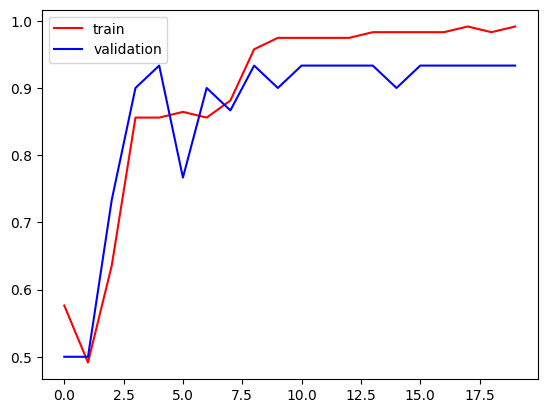

In [11]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], color = 'red', label ='train')
plt.plot(history.history['val_accuracy'], color = 'blue', label ='validation')
plt.legend()
plt.show()

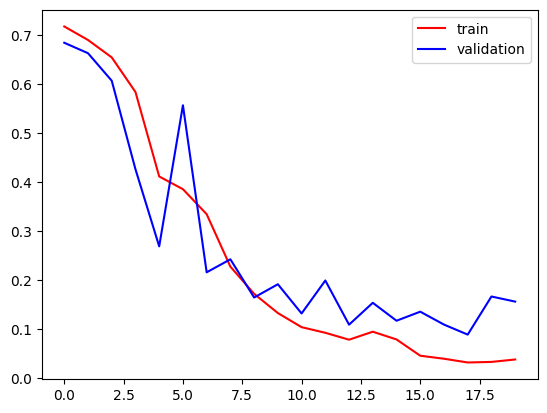

In [12]:
plt.plot(history.history['loss'], color = 'red', label ='train')
plt.plot(history.history['val_loss'], color = 'blue', label ='validation')
plt.legend()
plt.show()

In [13]:
X_test = []
Y_test = []
for file, label in [('NORMAL', 0),('PNEUMONIA',1)]:
    for file in (path_dir/ "test"/file).iterdir():
        img  = cv2.imread(file, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (128, 128))
        X_test.append(img)
        Y_test.append(label)
X_test = np.stack(X_test).astype(np.float32)/255
Y_test = np.array(Y_test)

In [14]:
X_test = X_test[..., None]

In [15]:
from sklearn.metrics import classification_report, confusion_matrix

print(model.evaluate(X_test, Y_test, verbose=0, return_dict=True))


prob = model.predict(X_test, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)


print("\nClassification report")
print(classification_report(
    Y_test, pred, labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"], digits=3, zero_division=0
))

print("Confusion matrix")
print(confusion_matrix(Y_test, pred, labels=[0, 1]))

{'loss': 0.02181920036673546, 'accuracy': 1.0}

Classification report
              precision    recall  f1-score   support

      NORMAL      1.000     1.000     1.000        20
   PNEUMONIA      1.000     1.000     1.000        20

    accuracy                          1.000        40
   macro avg      1.000     1.000     1.000        40
weighted avg      1.000     1.000     1.000        40

Confusion matrix
[[20  0]
 [ 0 20]]
